In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

In [2]:
childcare_prices = pd.read_excel("nationaldatabaseofchildcareprices.xlsx")

print(childcare_prices.info())
childcare_prices.head()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 34567 entries, 0 to 34566
Columns: 227 entries, State_Name to _75FCCPreschool_flag
dtypes: float64(159), int64(65), object(3)
memory usage: 59.9+ MB
None


,State_Name,State_Abbreviation,County_Name,County_FIPS_Code,StudyYear,UNR_16,FUNR_16,MUNR_16,UNR_20to64,FUNR_20to64,...,MFCCToddler,MFCCToddler_flag,MFCCPreschool,MFCCPreschool_flag,_75FCCInfant,_75FCCInfant_flag,_75FCCToddler,_75FCCToddler_flag,_75FCCPreschool,_75FCCPreschool_flag
0,Alabama,AL,Autauga County,1001,2008,5.42,4.41,6.32,4.6,3.5,...,83.45,3.0,81.40,1.0,97.4,1.0,97.4,3.0,95.0,1.0
1,Alabama,AL,Autauga County,1001,2009,5.93,5.72,6.11,4.8,4.6,...,87.39,3.0,85.68,1.0,102.0,1.0,102.0,3.0,100.0,1.0
2,Alabama,AL,Autauga County,1001,2010,6.21,5.57,6.78,5.1,4.6,...,91.33,3.0,89.96,1.0,106.6,1.0,106.6,3.0,105.0,1.0
3,Alabama,AL,Autauga County,1001,2011,7.55,8.13,7.03,6.2,6.3,...,95.28,3.0,94.25,1.0,111.2,1.0,111.2,3.0,110.0,1.0
4,Alabama,AL,Autauga County,1001,2012,8.60,8.88,8.29,6.7,6.4,...,99.22,3.0,98.53,1.0,115.8,1.0,115.8,3.0,115.0,1.0


In [3]:
childcare_prices.columns.tolist()

['State_Name',
 'State_Abbreviation',
 'County_Name',
 'County_FIPS_Code',
 'StudyYear',
 'UNR_16',
 'FUNR_16',
 'MUNR_16',
 'UNR_20to64',
 'FUNR_20to64',
 'MUNR_20to64',
 'FLFPR_20to64',
 'FLFPR_20to64_Under6',
 'FLFPR_20to64_6to17',
 'FLFPR_20to64_Under6_6to17',
 'MLFPR_20to64',
 'PR_F',
 'PR_P',
 'MHI',
 'ME',
 'FME',
 'MME',
 'MHI_2018',
 'ME_2018',
 'FME_2018',
 'MME_2018',
 'TotalPop',
 'OneRace',
 'OneRace_W',
 'OneRace_B',
 'OneRace_I',
 'OneRace_A',
 'OneRace_H',
 'OneRace_Other',
 'TwoRaces',
 'Hispanic',
 'Households',
 'H_Under6_BothWork',
 'H_Under6_FWork',
 'H_Under6_MWork',
 'H_Under6_SingleM',
 'H_6to17_BothWork',
 'H_6to17_Fwork',
 'H_6to17_Mwork',
 'H_6to17_SingleM',
 'EMP_M',
 'MEMP_M',
 'FEMP_M',
 'EMP_Service',
 'MEMP_Service',
 'FEMP_Service',
 'EMP_Sales',
 'MEMP_Sales',
 'FEMP_Sales',
 'EMP_N',
 'MEMP_N',
 'FEMP_N',
 'EMP_P',
 'MEMP_P',
 'FEMP_P',
 'iUNR_16',
 'iFUNR_16',
 'iMUNR_16',
 'iUNR_20to64',
 'iFUNR_20to64',
 'iMUNR_20to64',
 'iFLFPR_20to64',
 'iFLFPR_2

In [4]:
#organize columns by type for easy reference
id_cols = ['State_Name', 'State_Abbreviation', 'County_Name', 'County_FIPS_Code', 'StudyYear']

price_median = ['MCInfant', 'MCToddler', 'MCPreschool', 'MFCCInfant', 'MFCCToddler', 'MFCCPreschool']

price_75th = ['_75CInfant', '_75CToddler', '_75CPreschool', '_75FCCInfant', '_75FCCToddler', '_75FCCPreschool']

flag_cols = ['MCInfant_flag', 'MCToddler_flag', 'MCPreschool_flag', 'MFCCInfant_flag', 'MFCCToddler_flag', 'MFCCPreschool_flag',
             '_75CInfant_flag', '_75CToddler_flag', '_75CPreschool_flag', '_75FCCInfant_flag', '_75FCCToddler_flag', '_75FCCPreschool_flag']

income_cols = ['MHI_2018', 'FME_2018', 'MME_2018']  # inflation-adjusted

lfpr_cols = ['FLFPR_20to64', 'FLFPR_20to64_Under6', 'FLFPR_20to64_6to17', 'MLFPR_20to64']

household_cols = ['H_Under6_BothWork', 'H_Under6_FWork', 'H_Under6_MWork', 'H_Under6_SingleM']

In [5]:
#what % of each price column is imputed?
imputation_rates = childcare_prices[flag_cols].mean().rename(lambda x: x.replace('_flag', '')).sort_values(ascending = False)

print(imputation_rates.round(3)) 

_75CInfant         1.926
MCInfant           1.900
_75FCCInfant       1.793
MFCCInfant         1.750
_75CPreschool      1.371
MCPreschool        1.368
MCToddler          1.315
_75CToddler        1.308
_75FCCPreschool    1.294
MFCCPreschool      1.288
_75FCCToddler      1.188
MFCCToddler        1.153
dtype: float64


In [6]:
#is imputation concentrated in certain states?
state_impute = (childcare_prices.groupby('State_Abbreviation')['MCInfant_flag'].mean().sort_values(ascending = False).head(15))

print(state_impute.round(3))

State_Abbreviation
MS    3.000
DE    3.000
TN    3.000
OK    3.000
NH    3.000
ID    3.000
GA    3.000
WY    3.000
DC    3.000
CO    3.000
AZ    3.000
PA    2.818
LA    2.816
WA    2.748
ME    2.714
Name: MCInfant_flag, dtype: float64


In [7]:
#missingness on key analytic columns
key_cols = price_median + income_cols + lfpr_cols
missing = childcare_prices[key_cols].isnull().mean().sort_values(ascending = False)

print(missing[missing > 0].round(3))

MFCCInfant       0.324
MFCCToddler      0.324
MFCCPreschool    0.324
MCInfant         0.317
MCToddler        0.317
MCPreschool      0.317
dtype: float64


In [8]:
#coverage by year
year_coverage = childcare_prices.groupby('StudyYear')[price_median].count()

print(year_coverage[['MCInfant']])

           MCInfant
StudyYear          
2008           1424
2009           1901
2010           1991
2011           1992
2012           2053
2013           2074
2014           2323
2015           2398
2016           2641
2017           2436
2018           2360


In [9]:
#create annual cost and affordability ratio
#weekly prices × 52 = annual cost
for col in price_median:
    childcare_prices[col + '_annual'] = childcare_prices[col] * 52

#create new columns with new ratios
childcare_prices['infant_pct_MHI'] = (childcare_prices['MCInfant_annual'] / childcare_prices['MHI_2018']) * 100
childcare_prices['toddler_pct_MHI'] = (childcare_prices['MCToddler_annual'] / childcare_prices['MHI_2018']) * 100
childcare_prices['preschool_pct_MHI'] = (childcare_prices['MCPreschool_annual'] / childcare_prices['MHI_2018']) * 100

In [10]:
#national median affordability ratio by year
affordability_trend = (childcare_prices.groupby('StudyYear')[['infant_pct_MHI', 'toddler_pct_MHI', 'preschool_pct_MHI']].median())

print(affordability_trend.round(1))

           infant_pct_MHI  toddler_pct_MHI  preschool_pct_MHI
StudyYear                                                    
2008                 13.4             12.1               11.3
2009                 13.1             11.8               11.2
2010                 13.3             11.9               11.3
2011                 13.9             12.4               11.8
2012                 14.4             12.9               12.2
2013                 14.9             13.5               12.7
2014                 15.2             13.6               12.9
2015                 15.6             14.0               13.1
2016                 15.3             13.8               13.0
2017                 15.6             14.1               13.1
2018                 16.1             14.5               13.5


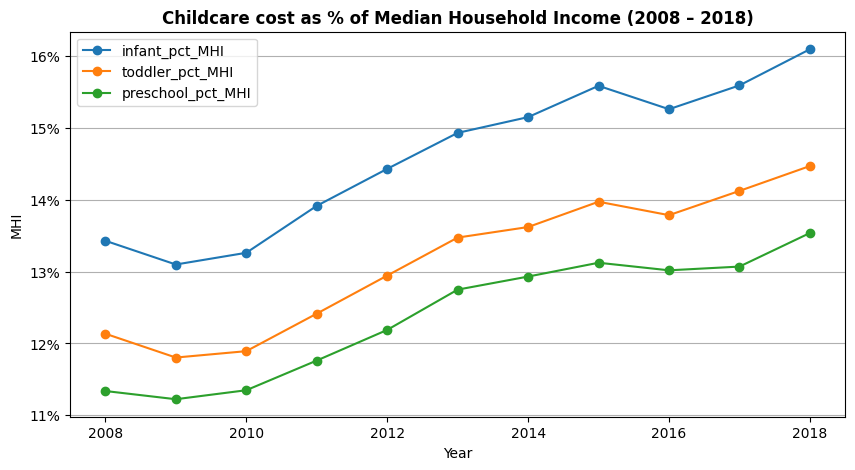

In [11]:
fig, ax = plt.subplots(figsize = (10, 5))
affordability_trend.plot(ax = ax, marker = 'o')

ax.set_title('Childcare cost as % of Median Household Income (2008 – 2018)', fontweight = 'bold')
ax.set_ylabel('MHI')
ax.set_xlabel('Year')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'{y:.0f}%'))

ax.grid(axis = 'y')
ax.legend()

#fig.savefig('Proj ppt - line chart')
plt.show()

In [12]:
#ratio: infant cost vs preschool cost
childcare_prices['infant_vs_preschool_ratio'] = childcare_prices['MCInfant'] / childcare_prices['MCPreschool']
ratio_by_year = childcare_prices.groupby('StudyYear')['infant_vs_preschool_ratio'].median()

print(ratio_by_year.round(2))

StudyYear
2008    1.21
2009    1.18
2010    1.15
2011    1.17
2012    1.17
2013    1.17
2014    1.15
2015    1.15
2016    1.15
2017    1.17
2018    1.16
Name: infant_vs_preschool_ratio, dtype: float64


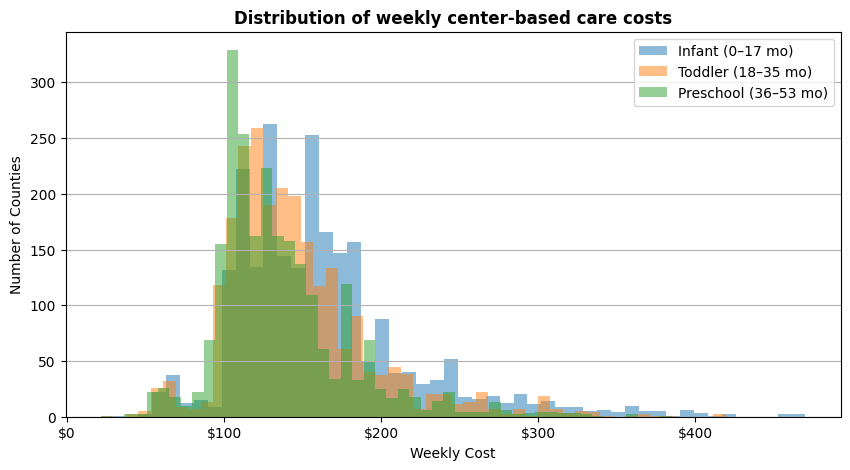

In [13]:
#distribution of care costs by age group (latest year)
latest_year = childcare_prices['StudyYear'].max()
latest = childcare_prices[childcare_prices['StudyYear'] == latest_year]

fig, ax = plt.subplots(figsize = (10, 5))
for col, label in zip(
    ['MCInfant', 'MCToddler', 'MCPreschool'],
    ['Infant (0–17 mo)', 'Toddler (18–35 mo)', 'Preschool (36–53 mo)']
):
    ax.hist(latest[col].dropna(), bins = 50, alpha = 0.5, label = label)

ax.set_title('Distribution of weekly center-based care costs', fontweight = 'bold')
ax.set_xlabel('Weekly Cost')
ax.set_ylabel('Number of Counties')

ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.grid(axis = 'y')
ax.legend()

#fig.savefig('Proj ppt - bar group')
plt.show()

In [14]:
#center-based vs home-based gap
childcare_prices['infant_center_vs_home'] = childcare_prices['MCInfant'] - childcare_prices['MFCCInfant']

print(childcare_prices.groupby('StudyYear')['infant_center_vs_home'].median().round(2))

StudyYear
2008    23.52
2009    20.66
2010    21.98
2011    25.00
2012    22.70
2013    24.66
2014    25.00
2015    26.95
2016    25.30
2017    29.21
2018    30.00
Name: infant_center_vs_home, dtype: float64


In [15]:
#correlation matrix: care costs vs FLFPR
corr_cols = ['MCInfant', 'MCToddler', 'MCPreschool', 'FLFPR_20to64', 'FLFPR_20to64_Under6', 'FLFPR_20to64_6to17', 'MHI_2018']
corr = childcare_prices[corr_cols].corr()

print(corr[['FLFPR_20to64_Under6']].round(3))

                     FLFPR_20to64_Under6
MCInfant                           0.096
MCToddler                          0.126
MCPreschool                        0.118
FLFPR_20to64                       0.533
FLFPR_20to64_Under6                1.000
FLFPR_20to64_6to17                 0.347
MHI_2018                           0.136


/var/folders/0t/gv42x13n5szd6n1r1b5m7qzm0000gn/T/ipykernel_77591/3897791276.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  flfpr_by_quartile = (childcare_prices.groupby('infant_cost_quartile')['FLFPR_20to64_Under6'].median())


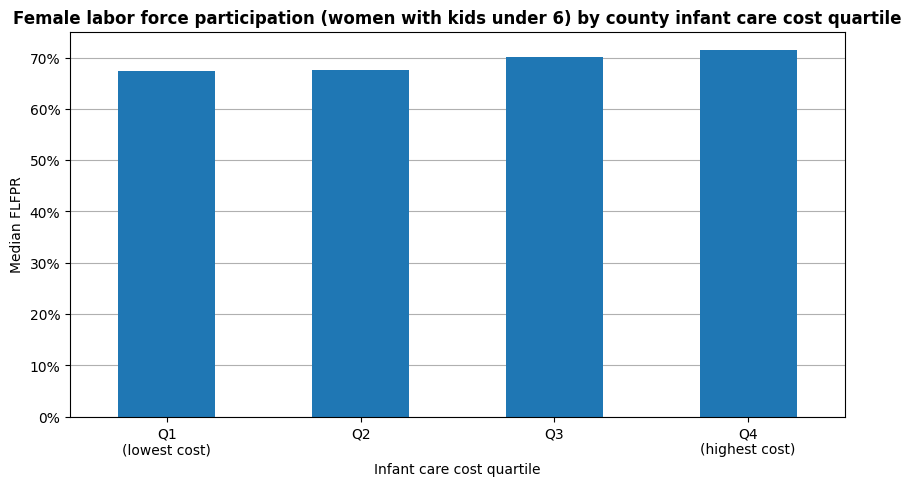

In [16]:
#bin counties by infant cost quartile, compare FLFPR
childcare_prices['infant_cost_quartile'] = pd.qcut(childcare_prices['MCInfant'], q = 4, 
                                                   labels = ['Q1\n(lowest cost)', 'Q2', 'Q3', 'Q4\n(highest cost)'])

flfpr_by_quartile = (childcare_prices.groupby('infant_cost_quartile')['FLFPR_20to64_Under6'].median())

fig, ax = plt.subplots(figsize = (10, 5))
flfpr_by_quartile.plot(kind = 'bar', ax = ax)

ax.set_title('Female labor force participation (women with kids under 6) by county infant care cost quartile', fontweight = 'bold')
ax.set_ylabel('Median FLFPR')
ax.set_xlabel('Infant care cost quartile')

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'{y:.0f}%'))
ax.tick_params(axis = 'x', rotation = 0)
ax.grid(axis = 'y')
ax.set_axisbelow(True)

#fig.savefig('Proj ppt - bar chart')
plt.show()

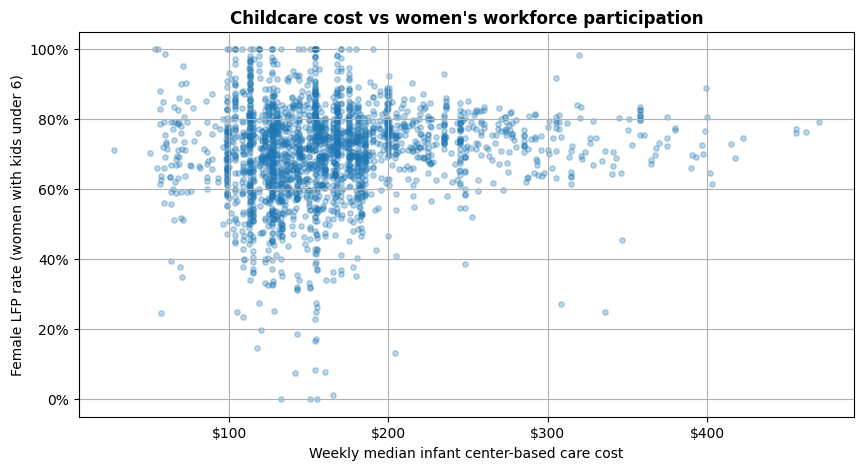

In [17]:
#scatter: infant cost vs FLFPR_Under6 (latest year)
fig, ax = plt.subplots(figsize = (10, 5))
ax.scatter(latest['MCInfant'], latest['FLFPR_20to64_Under6'], alpha = 0.3, s = 15)
ax.set_xlabel('Weekly median infant center-based care cost')
ax.set_ylabel('Female LFP rate (women with kids under 6)')
ax.set_title('Childcare cost vs women\'s workforce participation', fontweight = 'bold')

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'{y:.0f}%'))
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.grid()

#fig.savefig('Proj ppt - scatter plot')
plt.show()

In [18]:
#most and least affordable states (latest year)
state_summary = (
    childcare_prices[childcare_prices['StudyYear'] == latest_year]
    .groupby('State_Abbreviation')
    .agg(
        median_infant_weekly = ('MCInfant', 'median'),
        median_MHI = ('MHI_2018', 'median'),
        median_FLFPR_under6 = ('FLFPR_20to64_Under6', 'median'))
    .assign(infant_pct_MHI = lambda x: (x['median_infant_weekly'] * 52 / x['median_MHI']) * 100)
    .sort_values('infant_pct_MHI', ascending = False))

print("Most burdensome states — infant care as % of household income:")
print(state_summary.head(10).round(1))

print("\nLeast burdensome states:")
print(state_summary.tail(10).round(1))

Most burdensome states — infant care as % of household income:
                    median_infant_weekly  median_MHI  median_FLFPR_under6  \
State_Abbreviation                                                          
CA                                 289.6     59157.5                 66.4   
AK                                 336.2     69706.0                 70.4   
WA                                 248.1     54852.0                 63.6   
HI                                 346.2     77117.0                 70.6   
MA                                 305.0     70922.5                 78.3   
CT                                 305.0     75317.5                 78.0   
NY                                 219.8     55890.0                 75.0   
VT                                 229.4     59231.0                 78.3   
NC                                 165.0     44954.0                 72.4   
AZ                                 177.5     48649.0                 57.2   

            

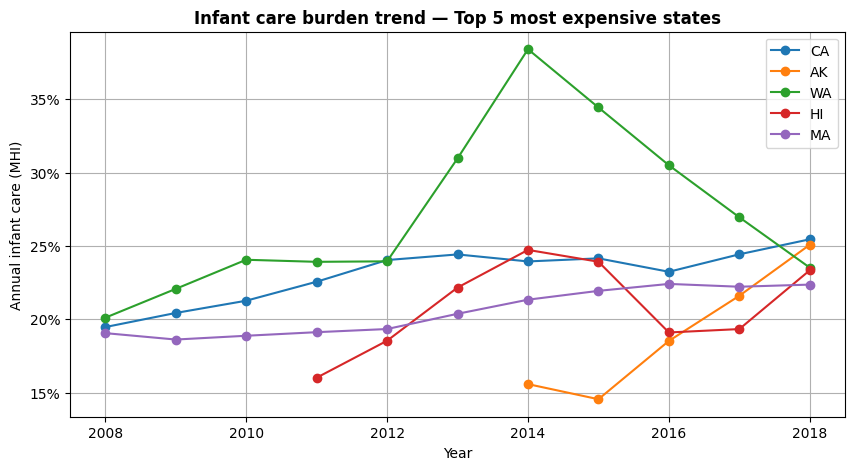

In [19]:
#state-level trend: has burden grown?
state_trend = (
    childcare_prices.groupby(['State_Abbreviation', 'StudyYear'])
    .agg(median_infant = ('MCInfant', 'median'),
         median_MHI    = ('MHI_2018', 'median'))
    .assign(pct_MHI = lambda x: (x['median_infant'] * 52 / x['median_MHI']) * 100).reset_index())

#plot top 5 most burdened states over time
top5_states = state_summary.head(5).index.tolist()
fig, ax = plt.subplots(figsize = (10, 5))
for state in top5_states:
    data = state_trend[state_trend['State_Abbreviation'] == state]
    ax.plot(data['StudyYear'], data['pct_MHI'], marker = 'o', label = state)

ax.set_title('Infant care burden trend — Top 5 most expensive states', fontweight = 'bold')
ax.set_ylabel('Annual infant care (MHI)')
ax.set_xlabel('Year')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda y, _: f'{y:.0f}%'))

ax.legend()
ax.grid()

#fig.savefig('Proj ppt - line burden')
plt.show()

In [20]:
#single-mother household counts vs care costs
childcare_prices['single_mom_share'] = (
    childcare_prices['H_Under6_SingleM'] / 
    (childcare_prices['H_Under6_BothWork'] + childcare_prices['H_Under6_FWork'] + 
     childcare_prices['H_Under6_MWork']   + childcare_prices['H_Under6_SingleM'])) * 100

#infant annual cost vs single-mom median earnings (FME_2018)
childcare_prices['infant_pct_FME'] = (childcare_prices['MCInfant_annual'] / childcare_prices['FME_2018']) * 100

print("Infant care as % of Female median earnings (vs household income):")
print(childcare_prices.groupby('StudyYear')[['infant_pct_MHI', 'infant_pct_FME']].median().round(1))

Infant care as % of Female median earnings (vs household income):
           infant_pct_MHI  infant_pct_FME
StudyYear                                
2008                 13.4            29.2
2009                 13.1            28.5
2010                 13.3            28.5
2011                 13.9            29.4
2012                 14.4            30.3
2013                 14.9            31.0
2014                 15.2            31.1
2015                 15.6            31.8
2016                 15.3            31.2
2017                 15.6            32.1
2018                 16.1            33.2


## Feedback from Milestone 1

Great work. Please keep in mind each medium should have a set of unique visualizations. Meaning, no crossover amongst them.

In [21]:
#national median infant cost and % of MHI for latest year
latest_year = childcare_prices['StudyYear'].max()
latest = childcare_prices[childcare_prices['StudyYear'] == latest_year]

print(latest['MCInfant'].median()) 
print(latest['infant_pct_MHI'].median())  
print((latest['infant_pct_MHI'] > 7).mean() * 100)  # % counties above HHS threshold

#four representative counties for the bar comparison
sample = latest[['County_Name', 'State_Abbreviation', 'MCInfant_annual', 'MHI_2018']].dropna()
sample['pct'] = sample['MCInfant_annual'] / sample['MHI_2018'] * 100

print(sample.nlargest(3, 'pct')[['County_Name','State_Abbreviation','MCInfant_annual','MHI_2018']])
print(sample.nsmallest(3, 'pct')[['County_Name','State_Abbreviation','MCInfant_annual','MHI_2018']])

#median weekly cost by age group
for col in ['MCInfant','MCToddler','MCPreschool']:
    print(col, latest[col].median())   #.round(2))

153.6
16.097198976252052
74.98408656906429
           County_Name State_Abbreviation  MCInfant_annual  MHI_2018
20139     Bronx County                 NY         20680.40   38085.0
20370     Kings County                 NY         20322.64   56015.0
2176   Humboldt County                 CA         15479.88   45528.0
           County_Name State_Abbreviation  MCInfant_annual  MHI_2018
17026    Mercer County                 MO          1441.96   44085.0
16663    DeKalb County                 MO          2614.04   50000.0
16344  Atchison County                 MO          3172.52   48385.0
MCInfant 153.6
MCToddler 140.0
MCPreschool 125.0


## Prepare data for Tableau

In [22]:
#build annual costs and affordability ratios
childcare_prices['MCInfant_annual'] = childcare_prices['MCInfant'] * 52
childcare_prices['MCToddler_annual'] = childcare_prices['MCToddler'] * 52
childcare_prices['MCPreschool_annual'] = childcare_prices['MCPreschool'] * 52

#keep only what the dashboard needs
dashboard_cols = [
    'State_Name', 'State_Abbreviation', 'County_Name', 'County_FIPS_Code', 'StudyYear', 'MCInfant', 
    'MCToddler', 'MCPreschool','MFCCInfant', 'MFCCToddler', 'MFCCPreschool', 'MCInfant_annual', 'MCToddler_annual', 
    'MCPreschool_annual', 'MHI_2018', 'FME_2018', 'infant_pct_MHI', 'toddler_pct_MHI', 'preschool_pct_MHI',
    'FLFPR_20to64_Under6', 'FLFPR_20to64', 'H_Under6_SingleM', 'H_Under6_BothWork', 'MCInfant_flag']

dashboard_df = childcare_prices[dashboard_cols].copy()

#fips needs to be zero-padded string for Tableau
dashboard_df['County_FIPS_Code'] = (dashboard_df['County_FIPS_Code'].astype(str).str.zfill(5))

dashboard_df.to_csv("childcare_dashboard.csv", index = False)
print(f"Exported: {dashboard_df.shape[0]:,} rows × {dashboard_df.shape[1]} columns")
print(dashboard_df['StudyYear'].value_counts().sort_index())

Exported: 34,567 rows × 24 columns
StudyYear
2008    3142
2009    3143
2010    3143
2011    3143
2012    3143
2013    3143
2014    3142
2015    3142
2016    3142
2017    3142
2018    3142
Name: count, dtype: int64


## Feedback from Milestone 2

Good work. I would make sure to have analysis and visuals on the same slide in a presentation mode.

## Feedback from Milestone 3

Good outline, a few comments. First, I would make the infographic a bit tighter. Meaning less white-spaces and shorter analysis for a reader. Secondly, visuals are duplicated across multiple mediums. Each medium needs its own set of visualizations.

In [23]:
#create state-level summary with one row per state
state_summary2 = (
    childcare_prices.groupby(['State_Abbreviation', 'State_Name'])
    .agg(
        median_infant_pct_MHI = ('infant_pct_MHI', 'median'),
        median_weekly_cost = ('MCInfant', 'median'),
        median_MHI = ('MHI_2018', 'median'),
        counties_above_7pct = ('infant_pct_MHI', lambda x: (x > 7).sum()),
        total_counties = ('infant_pct_MHI', 'count')
    )
    .reset_index().sort_values('median_infant_pct_MHI', ascending = False))

#verify — top 5 states should be in the 18-25% range
#state_summary2.to_csv('state_summary.csv', index = False)
print(state_summary2[['State_Abbreviation', 'median_infant_pct_MHI', 'counties_above_7pct', 'total_counties']].head(10))

   State_Abbreviation  median_infant_pct_MHI  counties_above_7pct  \
47                 WA              25.220614                  429   
4                  CA              23.188033                  638   
19                 MA              22.379706                  154   
7                  DC              22.330363                    1   
5                  CO              21.191908                   64   
34                 NY              20.650086                   62   
27                 NC              18.828654                  496   
39                 RI              18.620869                    5   
11                 HI              18.177711                    8   
21                 ME              17.929965                  112   

    total_counties  
47             429  
4              638  
19             154  
7                1  
5               64  
34              62  
27             496  
39               5  
11               8  
21             112  


In [24]:
#count distinct counties where infant_pct_MHI > 7
latest = childcare_prices[childcare_prices['StudyYear'] == childcare_prices['StudyYear'].max()]
counties_above = (latest['infant_pct_MHI'] > 7).sum()
total_counties = latest['infant_pct_MHI'].notna().sum()
pct_above = counties_above / total_counties * 100

print(f"Latest year: {childcare_prices['StudyYear'].max()}")
print(f"Counties above 7% threshold: {counties_above:,}")
print(f"Total counties with data: {total_counties:,}")
print(f"Percentage above threshold: {pct_above:.1f}%")

Latest year: 2018
Counties above 7% threshold: 2,356
Total counties with data: 2,360
Percentage above threshold: 99.8%


In [25]:
latest_year = childcare_prices['StudyYear'].max()
print(f"Latest year: {latest_year}")

#latest year only for KPI accuracy
latest2 = childcare_prices[childcare_prices['StudyYear'] == latest_year]

#correct county count above 7%
counties_above2 = int((latest2['infant_pct_MHI'] > 7).sum())
total_counties2 = int(latest2['infant_pct_MHI'].notna().sum())
pct_above2 = round(counties_above / total_counties * 100, 1)
national_median_pct_MHI = round(latest2['infant_pct_MHI'].median(), 1)
national_median_weekly_cost = round(latest2['MCInfant'].median(), 2)

print(f"\nKPI Values for {latest_year}:")
print(f"  Median weekly infant cost: ${national_median_weekly_cost}")
print(f"  Median infant % of MHI: {national_median_pct_MHI}%")
print(f"  Counties above 7% threshold: {counties_above:,}")
print(f"  Total counties with data: {total_counties:,}")
print(f"  % of counties above threshold: {pct_above}%")

#save a KPI summary — single row for easy Tableau reference
kpi_summary = pd.DataFrame([{
    'latest_year': latest_year, 'median_weekly_cost': national_median_weekly_cost,
    'median_infant_pct_MHI': national_median_pct_MHI, 'counties_above_threshold': counties_above,
    'total_counties': total_counties, 'pct_counties_above': pct_above}])

#kpi_summary.to_csv('kpi_summary.csv', index = False)
print("\nKPI Summary:")
print(kpi_summary.to_string(index = False))

Latest year: 2018

KPI Values for 2018:
  Median weekly infant cost: $153.6
  Median infant % of MHI: 16.1%
  Counties above 7% threshold: 2,356
  Total counties with data: 2,360
  % of counties above threshold: 99.83050847457628%

KPI Summary:
 latest_year  median_weekly_cost  median_infant_pct_MHI  counties_above_threshold  total_counties  pct_counties_above
        2018               153.6                   16.1                      2356            2360           99.830508


In [26]:
df = pd.read_csv('childcare_dashboard.csv')

#show all columns that contain 'pct' or 'MHI'
pct_cols = [col for col in df.columns if 'pct' in col.lower() or 'mhi' in col.lower()]
print("Columns with 'pct' or 'MHI':")
for col in pct_cols:
    print(f"  '{col}'")

Columns with 'pct' or 'MHI':
  'MHI_2018'
  'infant_pct_MHI'
  'toddler_pct_MHI'
  'preschool_pct_MHI'


In [27]:
#year level summary 
year_summary = (
    childcare_prices.groupby('StudyYear')
    .agg(
        median_infant_pct_MHI = ('infant_pct_MHI', 'median'),
        median_toddler_pct_MHI = ('toddler_pct_MHI', 'median'),
        median_preschool_pct_MHI = ('preschool_pct_MHI', 'median'),
    )
    .reset_index())

#year_summary.to_csv('year_summary.csv', index = False)
print(year_summary.to_string(index = False))

 StudyYear  median_infant_pct_MHI  median_toddler_pct_MHI  median_preschool_pct_MHI
      2008              13.429377               12.134714                 11.336662
      2009              13.098743               11.802951                 11.222463
      2010              13.262039               11.891862                 11.347761
      2011              13.915773               12.414517                 11.761119
      2012              14.430940               12.944602                 12.187818
      2013              14.932163               13.473802                 12.748876
      2014              15.151670               13.620589                 12.930885
      2015              15.587669               13.973054                 13.123300
      2016              15.261636               13.785948                 13.017851
      2017              15.593318               14.123937                 13.069939
      2018              16.097199               14.470398                 13